In [433]:
%pip install pandas
%pip install numpy
%pip install requests
%pip install matplotlib
%pip install scipy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [434]:
import pandas as pd
import numpy as np
from datetime import datetime, timezone
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import pearsonr 
import requests
import json
import math

Shutdown Data Visualization

In [435]:
shutdowns_df = pd.read_csv("internet-society-pulse-shutdowns.csv")
shutdowns_df

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services
0,IN,2026-10-09 14:00:00+00:00,2026-10-10 14:00:00+00:00,regional,unconfirmed,protests,National Capital Territory of Delhi,Mobile Internet
1,IN,2026-10-02 01:00:00+00:00,2026-10-02 13:00:00+00:00,regional,unconfirmed,protests,National Capital Territory of Delhi,Mobile Internet
2,IQ,2026-09-28 03:20:00+00:00,2026-09-28 04:10:00+00:00,national,acknowledged,exams,NaN,NaN
3,IN,2026-09-27 16:00:00+00:00,2026-09-28 14:00:00+00:00,regional,unconfirmed,protests,Punjab,Mobile Internet
4,IQ,2026-09-26 03:20:00+00:00,2026-09-26 04:10:00+00:00,national,acknowledged,exams,NaN,NaN
...,...,...,...,...,...,...,...,...
973,IN,2019-01-05 00:00:00+00:00,2019-01-05 00:00:00+00:00,regional,confirmed,government_action,Jammu and Kashmir,NaN
974,IN,2019-01-03 00:00:00+00:00,2019-01-03 00:00:00+00:00,regional,unconfirmed,government_action,Jammu and Kashmir,Mobile Internet Services
975,IN,2019-01-02 00:00:00+00:00,2019-01-02 00:00:00+00:00,regional,unconfirmed,government_action,Jammu and Kashmir,Mobile Internet Services
976,CN,2019-01-01 00:00:00+00:00,NaN,content_blocking,confirmed,government_action,NaN,"WhatsApp, LinkedIn, YouTube, Reddit, Google, F..."


In [436]:
shutdowns_df["cause"].value_counts()

cause
government_action    401
exams                353
protests             147
war_conflict          41
elections             36
Name: count, dtype: int64

In [437]:
shutdowns_df["end_date_dt"] = shutdowns_df["end_date"].map(lambda x: datetime.fromisoformat(x) if isinstance(x, str) else datetime.now(timezone.utc))
shutdowns_df["start_date_dt"] = shutdowns_df["start_date"].map(lambda x: datetime.fromisoformat(x))
shutdowns_df["year"] = shutdowns_df["start_date_dt"].map(lambda x: x.year)
shutdowns_df["duration"] = shutdowns_df["end_date_dt"] - shutdowns_df["start_date_dt"]
shutdowns_df["duration_hours"] = shutdowns_df["duration"].dt.total_seconds() / 3600

In [438]:
exam_excluded_df = shutdowns_df[shutdowns_df["cause"] != "exams"]
country_grouped = exam_excluded_df.groupby("country")
multiple_shutdowns = country_grouped.filter(lambda x: len(x) > 5)
multiple_shutdowns.sort_values("country").reset_index(drop=True)

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services,end_date_dt,start_date_dt,year,duration,duration_hours
0,BD,2019-12-31 00:00:00+00:00,2020-01-02 00:00:00+00:00,regional,unconfirmed,government_action,"Rangpur, Rajshahi, Khulna","Mobile Internet Services, SMS",2020-01-02 00:00:00+00:00,2019-12-31 00:00:00+00:00,2019,2 days 00:00:00,48.0
1,BD,2019-09-09 00:00:00+00:00,2020-08-28 00:00:00+00:00,regional,unconfirmed,government_action,Chittagong,Internet Services,2020-08-28 00:00:00+00:00,2019-09-09 00:00:00+00:00,2019,354 days 00:00:00,8496.0
2,BD,2023-10-28 11:00:00+00:00,2023-10-28 20:00:00+00:00,regional,acknowledged,protests,Dhaka,Internet Services,2023-10-28 20:00:00+00:00,2023-10-28 11:00:00+00:00,2023,0 days 09:00:00,9.0
3,BD,2019-09-02 00:00:00+00:00,2019-09-09 00:00:00+00:00,regional,unconfirmed,government_action,Chittagong,Mobile Internet Services,2019-09-09 00:00:00+00:00,2019-09-02 00:00:00+00:00,2019,7 days 00:00:00,168.0
4,BD,2024-08-04 07:30:00+00:00,2024-08-05 07:30:00+00:00,national,confirmed,protests,NaN,Internet Services,2024-08-05 07:30:00+00:00,2024-08-04 07:30:00+00:00,2024,1 days 00:00:00,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
518,YE,2020-10-15 00:00:00+00:00,2020-10-15 01:00:00+00:00,regional,unconfirmed,government_action,Hadhramaut,Internet Services,2020-10-15 01:00:00+00:00,2020-10-15 00:00:00+00:00,2020,0 days 01:00:00,1.0
519,YE,2020-08-19 00:00:00+00:00,2020-08-19 04:00:00+00:00,regional,unconfirmed,war_conflict,Zanzibar,Internet Services,2020-08-19 04:00:00+00:00,2020-08-19 00:00:00+00:00,2020,0 days 04:00:00,4.0
520,YE,2020-01-30 00:00:00+00:00,2020-02-26 00:00:00+00:00,national,unconfirmed,government_action,NaN,Internet Services,2020-02-26 00:00:00+00:00,2020-01-30 00:00:00+00:00,2020,27 days 00:00:00,648.0
521,YE,2022-01-20 21:30:00+00:00,2022-01-24 00:00:00+00:00,national,confirmed,war_conflict,NaN,Internet Services,2022-01-24 00:00:00+00:00,2022-01-20 21:30:00+00:00,2022,3 days 02:30:00,74.5


In [439]:
multiple_shutdowns["country"].value_counts()

country
IN    407
PK     18
VE     18
IR     16
BD     10
ET      9
MM      9
IQ      8
SD      8
YE      8
MZ      6
BY      6
Name: count, dtype: int64

/var/folders/qy/ty38b_c12590n_rw3ygn59840000gn/T/ipykernel_87982/3800718681.py:14: UserWarning: no explicit representation of timezones available for np.datetime64
  corr = pearsonr(np.array(x, dtype=np.datetime64).astype(np.int64), y)


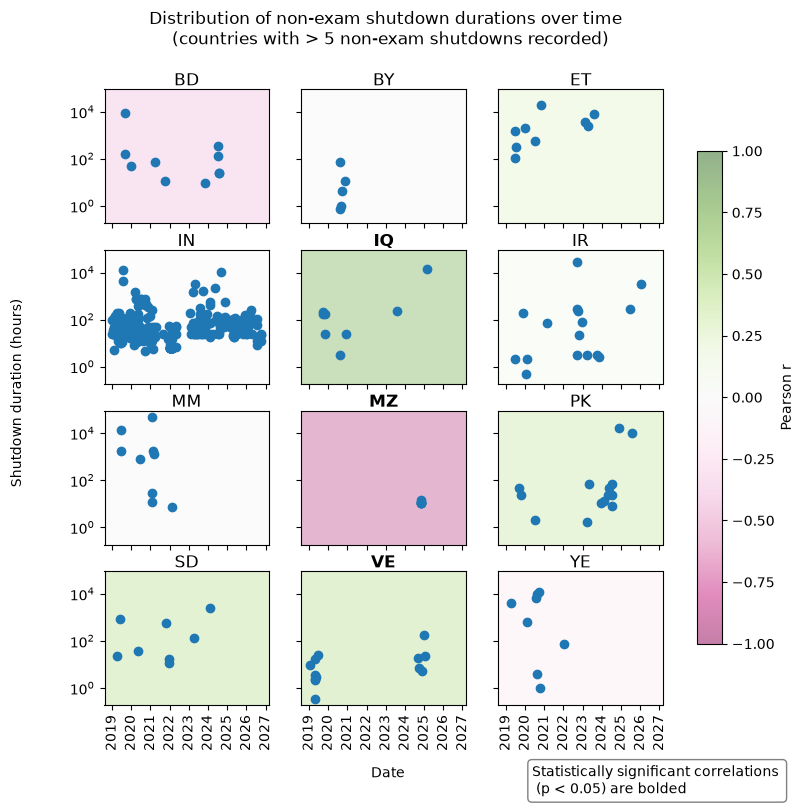

In [440]:
nrows = 4
ncols = 3
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2 * nrows), sharex=True, sharey=True)

cmap = mpl.colormaps["PiYG"]
norm = mpl.colors.Normalize(vmin=-1, vmax=1)
for ax, (name, group) in zip(axes.flat, multiple_shutdowns.groupby("country")):
    x = group["start_date_dt"]
    y = group["duration_hours"]
    ax.scatter(x, y)
    ax.set_yscale('log')
    ax.tick_params("x", rotation=90)

    corr = pearsonr(np.array(x, dtype=np.datetime64).astype(np.int64), y)
    ax.set_facecolor(cmap(norm(corr.statistic), alpha=0.3))
    if (corr.pvalue < 0.05):
        ax.set_title(name, fontweight="bold", pad=-5)
    else:
        ax.set_title(name, pad=-5)

fig.suptitle("Distribution of non-exam shutdown durations over time \n (countries with > 5 non-exam shutdowns recorded)", x=0.44)
fig.text(0.44, 0.02, "Date", ha="center")
fig.text(0.02, 0.5, "Shutdown duration (hours)", va="center", rotation="vertical")
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="Pearson r", alpha=0.5, shrink=0.8)
fig.text(0.6, 0, "Statistically significant correlations \n (p < 0.05) are bolded", bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey"))

plt.savefig("output/shutdown_duration_trends.png")

In [441]:
multiple_shutdowns_ve = multiple_shutdowns[multiple_shutdowns["country"] == "VE"]
shutdown_groups = multiple_shutdowns_ve.groupby(multiple_shutdowns_ve["year"].apply(lambda x: "2019" if x == 2019 else "2024-2025"))
shutdown_groups.first()

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services,end_date_dt,start_date_dt,year,duration,duration_hours
year,,,,,,,,,,,,,
2019,VE,2019-11-16 00:00:00+00:00,2019-11-16 00:00:00+00:00,content_blocking,confirmed,protests,NaN,"YouTube, X (Twitter), Facebook, Instagram",2019-11-16 00:00:00+00:00,2019-11-16 00:00:00+00:00,2019,0 days,0.0
2024-2025,VE,2025-01-10 00:00:00+00:00,2025-01-11 00:00:00+00:00,content_blocking,confirmed,elections,NaN,"Telegram, X (Twitter), Signal",2025-01-11 00:00:00+00:00,2025-01-10 00:00:00+00:00,2025,1 days,24.0


/var/folders/qy/ty38b_c12590n_rw3ygn59840000gn/T/ipykernel_87982/4261430958.py:2: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  shutdown_groups.boxplot(column="duration_hours", ax=axes)


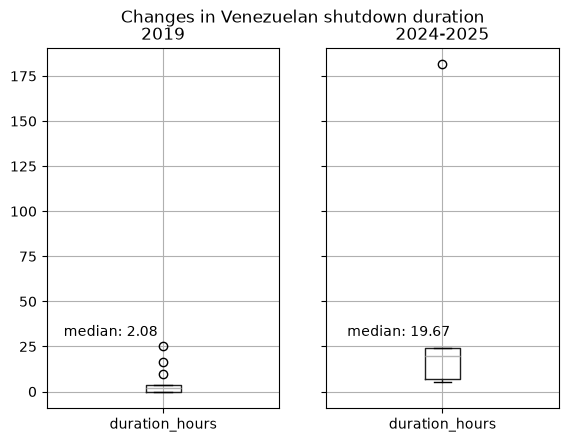

In [442]:
fig, axes = plt.subplots(1,1)
shutdown_groups.boxplot(column="duration_hours", ax=axes)
group_1_med = shutdown_groups.get_group("2019")["duration_hours"].median()
group_2_med = shutdown_groups.get_group("2024-2025")["duration_hours"].median()
fig.suptitle("Changes in Venezuelan shutdown duration")
fig.text(0.2, 0.3, f"median: {group_1_med:.2f}", ha="center")
fig.text(0.65, 0.3, f"median: {group_2_med:.2f}", ha="center")
plt.savefig("output/VE_boxplot.png")

Pull relevant API data

In [ ]:
PRIV_API_KEY = ""
header = {'Authorization': f'Bearer {PRIV_API_KEY}'}
relevant_years = multiple_shutdowns["year"].value_counts().index
url = "https://pulse-heart.internetsociety.org"

In [444]:
population_dict = {}
population_df = pd.DataFrame()

for year in relevant_years:
    endpoint=f"/population/{year}"
    res = requests.get(f'{url}{endpoint}', headers=header)
    year_dict = json.loads(res.text)
    year_df = pd.DataFrame.from_dict(year_dict["data"])
    population_df = pd.concat([population_df, year_df])
    population_dict[f"data_{year}"] = year_dict.pop("data")

with open('output/population.json', 'w') as f:
    json.dump(population_dict, f)

In [445]:
internet_use_dict = {}
internet_use_df = pd.DataFrame()

for year in relevant_years:
    endpoint=f"/internet-use/{year}"
    res = requests.get(f'{url}{endpoint}', headers=header)
    year_dict = json.loads(res.text)
    year_df = pd.DataFrame.from_dict(year_dict["data"])
    internet_use_df = pd.concat([internet_use_df, year_df])
    internet_use_dict[f"data_{year}"] = year_dict.pop("data")

with open('output/internet_use.json', 'w') as f:
    json.dump(internet_use_dict, f)

Create data column

In [446]:
overview_df = internet_use_df[internet_use_df["measure"] == "overview"]
merged_df = pd.merge(overview_df, population_df, how='inner', on=("year", "country_code"))
merged_df.rename(columns={'country_code': "country"}, inplace=True)
merged_df["num_affected"] = merged_df["value_x"] * merged_df["value_y"]
merged_df["num_affected"] = merged_df["num_affected"].map(lambda x: math.floor(x))
merged_df

,year,country,value_x,measure,last_retrieved_x,last_changed_x,value_y,last_retrieved_y,last_changed_y,num_affected
0,2019,AL,0.6855,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,2567801,2026-10-03T05:30:42.877Z,2026-01-03T01:55:41.945Z,1760227
1,2019,AF,0.1760,overview,2026-08-04T08:42:00.010Z,NaN,37856121,2026-10-03T05:30:42.671Z,2025-08-06T10:02:53.281Z,6662677
2,2019,DZ,0.5579,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,43294546,2026-10-03T05:30:43.098Z,2025-08-06T10:02:53.790Z,24154027
3,2019,AO,0.3213,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,32375632,2026-10-03T05:30:43.831Z,2025-08-06T10:02:54.566Z,10402290
4,2019,AG,0.7109,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,91364,2026-10-03T05:30:44.138Z,2025-08-06T10:02:55.001Z,64950
...,...,...,...,...,...,...,...,...,...,...
1136,2021,GB,0.9620,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,66978000,2026-10-03T05:31:21.798Z,2026-07-03T02:52:00.720Z,64432836
1137,2021,UA,0.7922,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,44298640,2026-10-03T05:31:21.506Z,2025-08-06T10:03:50.369Z,35093382
1138,2021,US,0.9127,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,332100166,2026-10-03T05:31:21.962Z,2026-07-03T02:52:08.089Z,303107821
1139,2021,CZ,0.8267,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,10505772,2026-10-03T05:30:52.611Z,2025-08-06T10:03:08.355Z,8685121


In [447]:
multiple_shutdowns_merged = pd.merge(multiple_shutdowns, merged_df, how="left", on=("year", "country"))
multiple_shutdowns_merged["hours_lost"] = multiple_shutdowns_merged["num_affected"] * multiple_shutdowns_merged["duration_hours"]
multiple_shutdowns_merged[multiple_shutdowns_merged["country"] == "VE"]

,country,start_date,end_date,type,verification_level,cause,affected_regions,affected_services,end_date_dt,start_date_dt,...,duration_hours,value_x,measure,last_retrieved_x,last_changed_x,value_y,last_retrieved_y,last_changed_y,num_affected,hours_lost
48,VE,2025-01-10 00:00:00+00:00,2025-01-11 00:00:00+00:00,content_blocking,confirmed,elections,NaN,"Telegram, X (Twitter), Signal",2025-01-11 00:00:00+00:00,2025-01-10 00:00:00+00:00,...,24.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49,VE,2025-01-04 10:30:00+00:00,2025-01-11 23:59:00+00:00,content_blocking,confirmed,elections,NaN,"X (Twitter), DNS, VPN services, Signal",2025-01-11 23:59:00+00:00,2025-01-04 10:30:00+00:00,...,181.483333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
53,VE,2024-11-23 10:30:00+00:00,2024-11-23 16:00:00+00:00,content_blocking,confirmed,elections,NaN,"Signal, X (Twitter), YouTube",2024-11-23 16:00:00+00:00,2024-11-23 10:30:00+00:00,...,5.500000,0.7668,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28405543.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,21781370.0,1.197975e+08
65,VE,2024-09-28 09:00:00+00:00,2024-09-28 16:00:00+00:00,content_blocking,confirmed,elections,NaN,"Signal, TikTok, X (Twitter)",2024-09-28 16:00:00+00:00,2024-09-28 09:00:00+00:00,...,7.000000,0.7668,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28405543.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,21781370.0,1.524696e+08
69,VE,2024-09-02 20:00:00+00:00,2024-09-03 15:40:00+00:00,content_blocking,confirmed,elections,NaN,"Signal, X (Twitter), Telegram",2024-09-03 15:40:00+00:00,2024-09-02 20:00:00+00:00,...,19.666667,0.7668,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28405543.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,21781370.0,4.283669e+08
390,VE,2019-11-16 00:00:00+00:00,2019-11-16 00:00:00+00:00,content_blocking,confirmed,protests,NaN,"YouTube, X (Twitter), Facebook, Instagram",2019-11-16 00:00:00+00:00,2019-11-16 00:00:00+00:00,...,0.000000,0.4905,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28938098.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,14194137.0,0.000000e+00
435,VE,2019-06-18 15:00:00+00:00,2019-06-19 16:00:00+00:00,content_blocking,unconfirmed,government_action,NaN,"X (Twitter), Instagram",2019-06-19 16:00:00+00:00,2019-06-18 15:00:00+00:00,...,25.000000,0.4905,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28938098.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,14194137.0,3.548534e+08
452,VE,2019-05-24 13:20:00+00:00,2019-05-24 16:18:00+00:00,content_blocking,acknowledged,government_action,NaN,"Periscope, YouTube",2019-05-24 16:18:00+00:00,2019-05-24 13:20:00+00:00,...,2.966667,0.4905,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28938098.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,14194137.0,4.210927e+07
459,VE,2019-05-15 16:30:00+00:00,2019-05-15 16:30:00+00:00,content_blocking,confirmed,government_action,NaN,"Instagram, Periscope",2019-05-15 16:30:00+00:00,2019-05-15 16:30:00+00:00,...,0.000000,0.4905,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28938098.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,14194137.0,0.000000e+00
464,VE,2019-05-05 23:59:00+00:00,2019-05-06 02:04:00+00:00,content_blocking,confirmed,government_action,NaN,"YouTube, Periscope, Instagram, X (Twitter)",2019-05-06 02:04:00+00:00,2019-05-05 23:59:00+00:00,...,2.083333,0.4905,overview,2026-08-04T08:42:00.010Z,2026-04-20T09:26:40.638Z,28938098.0,2026-10-03T05:31:22.639Z,2025-08-06T10:03:52.258Z,14194137.0,2.957112e+07


**Finding: lack of internet usage data for many countries 2025 onwards**